# ENBW of the E7405A RBW 1 MHz filter

The noise power the SA reports in one RBW is $P = k_B T\,B_N\,G$, where $B_N$ is the **equivalent noise
bandwidth** (ENBW) of the RBW filter, not its nominal (−3 dB) width. Every hot-wire temperature in
`yfactor_fit.ipynb` scales as $1/B_N$, so $B_N$ is measured here from a CW tone swept through the filter.

**Measurement (2026-10-15)**: SynthHD probe, 0 dBm at 5.576 GHz (a clean tone; do not use the ZVA, whose CW output
has a ~12 kHz sideband comb that widens the filter), RCDAT 5 dB, through the fridge to the SA.
SA: span 10 MHz, RBW 1 MHz, VBW 1 kHz, sample detector, LOG, **reference level −10 dBm** (peak −26 dBm, below the
reference level; with the peak above it the shape distorts), live-view average of 22 traces (power average).
The tone is 50 dB above the noise floor.

## Theory

**ENBW.** For a filter with power response $|H(f)|^2$, the ENBW is the width of a rectangular filter with the
same peak gain that passes the same white-noise power:

$$B_N = \frac{\int |H(f)|^2\,df}{|H(f_0)|^2}$$

A CW tone at $f_t$ seen through the filter at center $f$ reads $P(f) = P_t\,|H(f-f_t)|^2$, so a swept trace of a
clean tone *is* the power response, and $B_N = \sum_i P_i\,\Delta f / P_\mathrm{peak}$ after removing the
noise floor.

**4-pole synchronously tuned filter.** The analog RBW filters of swept SAs like the E7405A are four identical
single-pole stages (AN 150, AN 1303):

$$|H(f)|^2 = \left[1 + (f/a)^2\right]^{-4}, \qquad
B_{3\,\mathrm{dB}} = 2a\sqrt{2^{1/4}-1}, \qquad
B_N = a\sqrt{\pi}\,\frac{\Gamma(7/2)}{\Gamma(4)} = \frac{5\pi}{16}\,a$$

so $B_N / B_{3\,\mathrm{dB}} = 1.128$ (0.52 dB), the value tabulated in AN 1303, and the 60 dB / 3 dB selectivity
is 12.7:1, as quoted in AN 150. The nominal RBW is the −3 dB width, but its accuracy is only ±15 % (datasheet),
so $B_N$ is taken from the measured trace and checked against $1.128 \times B_{3\,\mathrm{dB}}$.

**Why this is done by hand.** The SA trace is calibrated for sinusoids. For noise it reads 2.51 dB low in LOG with
video averaging (corrected in `yfactor_fit.ipynb`), and it is the power in $B_N$, not in the nominal RBW. The SA's
own *noise marker* applies both corrections, but with 1.128 × the nominal RBW; measuring $B_N$ uses the actual
filter.

**References**
- Agilent AN 1303, *Spectrum Analyzer Measurements and Noise* (5966-4008E):
  [PDF copy](https://rose-hulman.edu/class/ee/voltmer/My%20DocumentsB/wireless/spec_analyz.pdf).
  Log-scale under-response 2.51 dB (p. 8); four-pole synchronously tuned RBW filters and the ENBW / −3 dB table,
  4-pole 1.128 (0.52 dB), and the noise marker (pp. 8–9).
- Keysight AN 150, *Spectrum Analysis Basics* (5952-0292):
  [PDF copy](https://xdevs.com/doc/HP_Agilent_Keysight/5952-0292%20English%20_%202014-02-25%20_%20PDF%205.71%20MB%20c20141003%20%5B89%5D.pdf).
  Four-pole synchronously tuned RBW filters, 12.7:1 selectivity (p. 14); noise 2.5 dB low in log mode and the
  noise marker (pp. 53–54).
- Agilent E7401A–E7405A EMC analyzer specifications:
  [PDF copy](https://nscainc.com/wp-content/uploads/pdf/A_E7400A.pdf). RBW 1 kHz–3 MHz accuracy ±15 % (p. 2).

In [1]:
import json
from math import pi, sqrt
import numpy as np
import matplotlib.pyplot as plt

## Parameters

In [2]:
DATA_FILE = "single_tone_measurement_SA.json"
FLOOR_DBM = -77.25    # SA noise floor measured seperately

## Load the trace

In [3]:
with open(DATA_FILE) as fh:
    d = json.load(fh)
t = d["trace"]
f = np.array(t["x"])
y = np.array(t["y"])                 # dBm
P = 10 ** (y / 10) * 1e-3            # W
df = f[1] - f[0]

print(f"span {t['span_hz']/1e6:g} MHz, RBW {t['rbw_hz']/1e6:g} MHz, VBW {t['vbw_hz']/1e3:g} kHz, {t['scale']}, "
      f"{t['averages']} averages, ref level {d['instruments']['spa']['ref_level']:g} dBm, "
      f"{len(f)} points, df = {df/1e3:g} kHz")
print(f"tone: SynthHD {d['instruments']['rf_synth']['probe_frequency_hz']/1e9:g} GHz, "
      f"{d['instruments']['rf_synth']['probe_power_dbm']:g} dBm, RCDAT {d['instruments']['attenuator']['attenuation_db']:g} dB")

span 10 MHz, RBW 1 MHz, VBW 1 kHz, LOG, 22 averages, ref level -10 dBm, 401 points, df = 25 kHz
tone: SynthHD 5.576 GHz, 0 dBm, RCDAT 5 dB


## ENBW and −3 dB width

In [4]:
# peak: parabola through the top 7 points in dB
ip = np.argmax(y)
c2, c1, c0 = np.polyfit(f[ip-3:ip+4] - f[ip], y[ip-3:ip+4], 2)
f_peak = f[ip] - c1 / (2 * c2)
y_peak = c0 - c1 ** 2 / (4 * c2)

floor_w = 10 ** (FLOOR_DBM / 10) * 1e-3
peak_w = 10 ** (y_peak / 10) * 1e-3 - floor_w
s = (P - floor_w) / peak_w           # |H|^2, normalized to 1 at the peak

enbw = s.sum() * df

# -3 dB width, interpolated on both sides
i = np.where(s >= 0.5)[0]
lo = np.interp(0.5, [s[i[0]-1], s[i[0]]], [f[i[0]-1], f[i[0]]])
hi = np.interp(0.5, [s[i[-1]+1], s[i[-1]]], [f[i[-1]+1], f[i[-1]]])
b3 = hi - lo

ratio_4pole = (5 * pi / 16) / (2 * sqrt(2 ** 0.25 - 1))
print(f"peak {y_peak:.2f} dBm at {f_peak/1e9:.6f} GHz, {y_peak - FLOOR_DBM:.1f} dB above the floor")
print(f"-3 dB width  B3 = {b3/1e6:.4f} MHz")
print(f"ENBW         BN = {enbw/1e6:.4f} MHz  (measured, area / peak)")
print(f"4-pole       BN = {ratio_4pole:.3f} x B3 = {ratio_4pole*b3/1e6:.4f} MHz  "
      f"(measured / 4-pole = {enbw/(ratio_4pole*b3):.4f})")
for dfl in (-0.5, 0.5):
    fw = 10 ** ((FLOOR_DBM + dfl) / 10) * 1e-3
    e = ((P - fw) / (10 ** (y_peak / 10) * 1e-3 - fw)).sum() * df
    print(f"   floor {dfl:+.1f} dB -> {e/1e6:.4f} MHz")

peak -26.17 dBm at 5.575974 GHz, 51.1 dB above the floor
-3 dB width  B3 = 1.0123 MHz
ENBW         BN = 1.1436 MHz  (measured, area / peak)
4-pole       BN = 1.128 x B3 = 1.1424 MHz  (measured / 4-pole = 1.0010)
   floor -0.5 dB -> 1.1436 MHz
   floor +0.5 dB -> 1.1436 MHz


## Shape vs the 4-pole filter

The model curve has the measured −3 dB width. The trace is slightly asymmetric: with VBW 1 kHz the video filter
(τ = 160 µs) smears the 16 ms sweep by about 100 kHz towards higher frequency, so the lower skirt falls a little
faster and the upper skirt a little slower than the model. The smearing acts on the log trace and lowers it by
nearly the same factor everywhere, so $B_N$ (area over peak) is hardly affected. A slower sweep (manual sweep
time ≥ 1 s) would remove it.

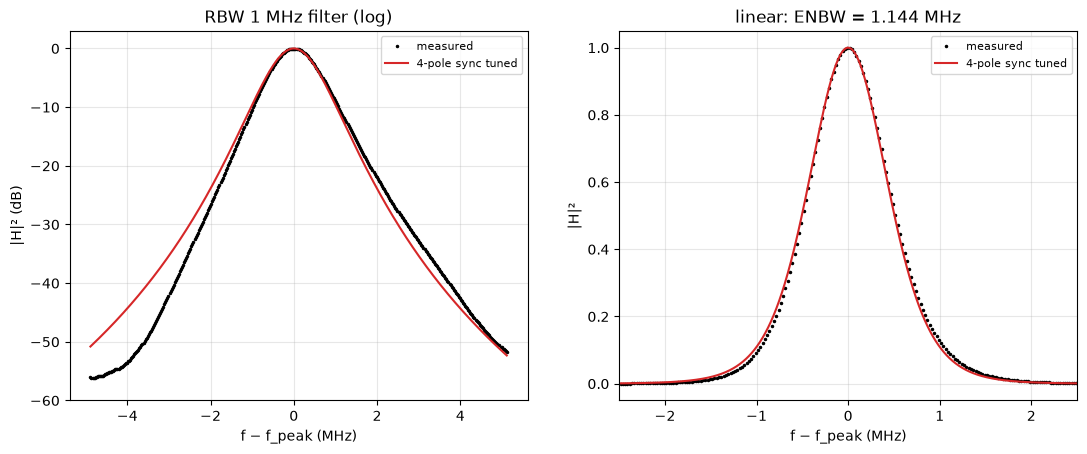

In [6]:
x = f - f_peak
xm = np.linspace(x[0], x[-1], 2001)
a = b3 / (2 * sqrt(2 ** 0.25 - 1))
model = (1 + (xm / a) ** 2) ** -4

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].plot(x / 1e6, 10 * np.log10(np.maximum(s, 1e-9)), "k.", ms=3, label="measured")
ax[0].plot(xm / 1e6, 10 * np.log10(model), "C3", label="4-pole sync tuned")
ax[1].plot(x / 1e6, s, "k.", ms=3, label="measured")
ax[1].plot(xm / 1e6, model, "C3", label="4-pole sync tuned")
ax[0].set(xlabel="f − f_peak (MHz)", ylabel="|H|² (dB)", ylim=(-60, 3), title="RBW 1 MHz filter (log)")
ax[1].set(xlabel="f − f_peak (MHz)", ylabel="|H|²", xlim=(-2.5, 2.5), title=f"linear: ENBW = {enbw/1e6:.3f} MHz")
for a_ in ax:
    a_.grid(alpha=0.3)
    a_.legend(fontsize=8)
plt.show()

## Result

Put the measured ENBW above (1.144 MHz on 2026-10-15) into `ENBW_HZ` in `yfactor_fit.ipynb`. It holds only for
RBW 1 MHz.